# MSE802 Assessment 2 — Task 2: Qiskit Circuits and a Custom QASM Circuit (Quokka)

| Item | Detail |
|---|---|
| Learning outcomes | LO1 (evaluate with the maths of quantum mechanics), LO2 (design circuits) |
| Shots | 1000 per run |

**Task question (Part A):** *Using Qiskit, generate the given circuit (H on the first line, X on the second line, both feeding block C). Measure the output on the Quokka device and print it.*

**Task question (Part B):** *Write a QASM script for a circuit of your own, with different qubits and various gates. Run it on Quokka and print the output.*

### Running in Google Colab?
Run the next cell first. In Colab it downloads the project from GitHub, installs the packages and moves into this task's folder. In VS Code / Jupyter it does nothing.

In [1]:
# ---------- Google Colab bootstrap (skipped automatically on your own PC) ----------
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/anishnz/quantumcomputing_YB_Anish.git"
REPO_DIR = Path("/content/quantumcomputing_YB_Anish")
TASK_DIR = "Task_2_Qiskit_QASM"
if "google.colab" in sys.modules and not (Path.cwd().parent / "common").exists():
    if not REPO_DIR.exists():                         # 1. download the project from GitHub
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",   # 2. install quantum packages
                    "cirq-core", "qiskit", "qiskit-aer", "pylatexenc"], check=True)
    os.chdir(REPO_DIR / "Assignment_2_Quantum" / TASK_DIR)     # 3. work inside this task's folder
print("Working folder:", Path.cwd())

Working folder: /home/claude/Assignment_2_Quantum/Task_2_Qiskit_QASM


## 0. Set-up

In [2]:
import sys                                   # to reach the shared helper in ../common
from pathlib import Path                     # file paths that work on Windows and Linux
import numpy as np                           # numbers and arrays
import pandas as pd                          # result tables
import matplotlib.pyplot as plt              # charts and circuit drawings
import qiskit                                # IBM's quantum SDK (required by the task)
import qiskit.qasm2                          # read/write OpenQASM 2.0 text
from qiskit import QuantumCircuit, transpile # circuit object and gate translation
from qiskit.quantum_info import Statevector  # exact (ideal) state for the theory column

sys.path.insert(0, str(Path.cwd().parent / "common"))
import quokka_helper as qh                   # team helper: Quokka call, fallback, counts, plots

SHOTS = 1000                                 # agreed number of shots
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
print("Qiskit version:", qiskit.__version__)
print("Quokka status :", qh.quokka_status())

Qiskit version: 2.6.1


Quokka status : offline (Quokka endpoint is offline (HTTP 404, ERR_NGROK_3200))


# Part A — The given circuit

## A1. What is block "C"?

In the brief, block **C** has **two inputs** (from H and from X) but only **one output arrow** (on the lower line). That is the textbook drawing of a **controlled-NOT (CNOT)** (confirmed by the lecturer) gate used as a *classical-style* function block: the upper line is the **control** and the lower line is the **target**, whose value is the circuit's output. We therefore build:

$$q_0:\ H \;\to\; \text{control},\qquad q_1:\ X \;\to\; \text{target (output)}$$

## A2. What should happen? (Step-by-step maths)

Qiskit writes states as $|q_1 q_0\rangle$ (highest qubit on the left).

| Step | Operation | State $|q_1 q_0\rangle$ |
|---|---|---|
| 0 | start | $|00\rangle$ |
| 1 | $H$ on $q_0$ | $\frac{1}{\sqrt2}(|00\rangle + |01\rangle)$ |
| 2 | $X$ on $q_1$ | $\frac{1}{\sqrt2}(|10\rangle + |11\rangle)$ |
| 3 | CNOT($q_0 \to q_1$) | $\frac{1}{\sqrt2}(|10\rangle + |01\rangle)$ |

The final state is the Bell state $|\Psi^+\rangle = \frac{1}{\sqrt2}(|01\rangle+|10\rangle)$: the two qubits are **entangled and always opposite**. Predictions:

* measuring both qubits: `01` ≈ 50 %, `10` ≈ 50 %, `00` = `11` = 0 %;
* measuring only the output line $q_1$: `0` ≈ 50 %, `1` ≈ 50 %.

## A3. Build the circuit in Qiskit

In [3]:
qc_a = QuantumCircuit(2, 2, name="Task2A")   # 2 qubits, 2 classical bits
qc_a.h(0)                                    # H on the top line (q0) -> superposition
qc_a.x(1)                                    # X on the bottom line (q1) -> |1>
qc_a.barrier()                               # visual separator before block C
qc_a.cx(0, 1)                                # block C = CNOT, control q0, target q1 (the output line)
qc_a.barrier()
qc_a.measure([0, 1], [0, 1])                 # read both lines: q0 -> c[0], q1 -> c[1]

fig = qc_a.draw("mpl")                       # nice drawing for the report
fig.savefig(RESULTS / "task2a_circuit.png", dpi=200, bbox_inches="tight")
print(qc_a.draw("text"))

     ┌───┐ ░       ░ ┌─┐   
q_0: ┤ H ├─░───■───░─┤M├───
     ├───┤ ░ ┌─┴─┐ ░ └╥┘┌─┐
q_1: ┤ X ├─░─┤ X ├─░──╫─┤M├
     └───┘ ░ └───┘ ░  ║ └╥┘
c: 2/═════════════════╩══╩═
                      0  1 


## A4. Ideal (theoretical) probabilities from the state vector

In [4]:
ideal_a = Statevector(qc_a.remove_final_measurements(inplace=False))   # exact state, no noise
theory_a = {str(k): round(float(v), 4) for k, v in ideal_a.probabilities_dict().items()}
print("Ideal state  :", ideal_a.draw("text"))
print("Theory probs :", theory_a)          # expected {'01': 0.5, '10': 0.5}

Ideal state  : [0.        +0.j,0.70710678+0.j,0.70710678+0.j,0.        +0.j]
Theory probs : {'01': 0.5, '10': 0.5}


## A5. Convert to QASM and run on Quokka (1000 shots)

In [5]:
qasm_a = qiskit.qasm2.dumps(qc_a)            # Qiskit -> OpenQASM 2.0 text
print(qh.clean_qasm(qasm_a))                 # what is actually sent (no include, no barrier)
run_a = qh.run_qasm(qasm_a, shots=SHOTS, label="task2a_both_qubits", save_dir=RESULTS)
print("Source :", run_a["source"])
print("Counts :", run_a["counts"])

OPENQASM 2.0;
qreg q[2];
creg c[2];
h q[0];
x q[1];
cx q[0],q[1];
measure q[0] -> c[0];
measure q[1] -> c[1];



Source : LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable
Counts : {'01': 492, '10': 508}


## A6. Measure only the output line (exactly as drawn in the brief)

The diagram shows one output arrow, so we also run a version that measures only $q_1$.

In [6]:
qc_out = QuantumCircuit(2, 1)                # same gates, one classical bit
qc_out.h(0); qc_out.x(1); qc_out.cx(0, 1)    # H, X, block C (CNOT)
qc_out.measure(1, 0)                         # only the output line q1 -> c[0]
run_out = qh.run_qasm(qiskit.qasm2.dumps(qc_out), shots=SHOTS, label="task2a_output_only", save_dir=RESULTS)
print("Source :", run_out["source"])
print("Output line counts:", run_out["counts"])   # expected about 500 '0' and 500 '1'

Source : LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable
Output line counts: {'0': 491, '1': 509}


## A7. Results and comparison

,Outcome |q1 q0>,Theory P,Counts (of 1000),Measured P,Difference
0,00,0.0,0,0.000,0.000
1,01,0.5,492,0.492,-0.008
2,10,0.5,508,0.508,0.008
3,11,0.0,0,0.000,0.000


TVD (theory vs measured): 0.008


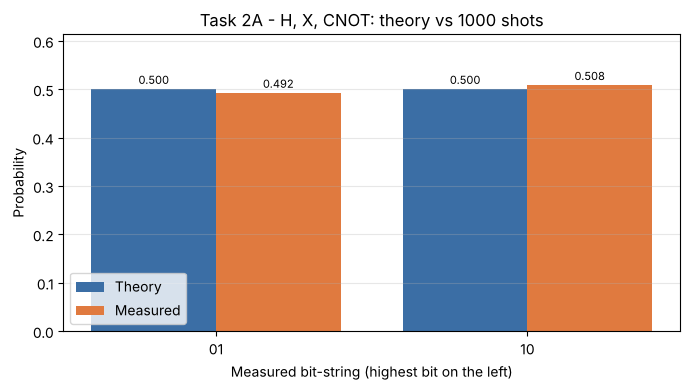

In [7]:
keys = ["00", "01", "10", "11"]
table_a = pd.DataFrame({
    "Outcome |q1 q0>": keys,
    "Theory P": [theory_a.get(k, 0.0) for k in keys],
    "Counts (of 1000)": [run_a["counts"].get(k, 0) for k in keys],
    "Measured P": [round(run_a["probs"].get(k, 0.0), 3) for k in keys],
})
table_a["Difference"] = (table_a["Measured P"] - table_a["Theory P"]).round(3)
display(table_a)
table_a.to_csv(RESULTS / "task2a_results_table.csv", index=False)
print("TVD (theory vs measured):", round(qh.total_variation_distance(theory_a, run_a["probs"]), 4))

qh.plot_comparison({"Theory": theory_a, "Measured": run_a["probs"]},
                   "Task 2A - H, X, CNOT: theory vs 1000 shots",
                   path=RESULTS / "task2a_histogram.png")
plt.show()

# Part B — Our own circuit written in QASM: a quantum half adder

## B1. Why this design? (Creativity with a purpose)

A **half adder** adds two bits A and B and returns **SUM = A XOR B** and **CARRY = A AND B**. In a normal computer you run it four times to see the whole truth table. Here the inputs are put into **superposition**, so one circuit holds all four additions at once. Each measurement then shows one complete row of the truth table, and 1000 shots show all rows with about 25 % each.

| Qubit | Role | Gates used and why |
|---|---|---|
| q0 | input A | **H** (superposition), **Z** (phase flip — teaches that phase is invisible to a direct measurement) |
| q1 | input B | **H**, **S** (quarter-turn phase — same lesson) |
| q2 | CARRY | **CCX / Toffoli** (A AND B) |
| q3 | SUM | two **CX** gates (A XOR B) |

Gates used: H, Z, S, CX, CCX (Toffoli), barrier, measure — five different gate types on four qubits.

In [8]:
qasm_b_file = Path("custom_half_adder.qasm")          # our hand-written QASM file
qasm_b = qasm_b_file.read_text()
print(qasm_b)

qc_b = qiskit.qasm2.loads(qasm_b)                     # check it is valid QASM by loading it in Qiskit
fig = qc_b.draw("mpl")
fig.savefig(RESULTS / "task2b_circuit.png", dpi=200, bbox_inches="tight")
print(qc_b.draw("text"))

// =====================================================================
// MSE802 Assessment 2 - Task 2 Part B : our own circuit, written in QASM
// "Quantum half adder in superposition"
// Group project: Anish Shrestha and Sandhya Tiwari
//
// Qubit roles:  q[0] = A (input)   q[1] = B (input)
//               q[2] = CARRY (A AND B)   q[3] = SUM (A XOR B)
// Idea: H gates put A and B into superposition, so ONE circuit adds
// 0+0, 0+1, 1+0 and 1+1 at the same time. Each shot shows one of them.
// =====================================================================
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];              // four qubits, all start in |0>
creg c[4];              // four classical bits for the results

h q[0];                 // A -> (|0> + |1>)/sqrt(2)
h q[1];                 // B -> (|0> + |1>)/sqrt(2)
z q[0];                 // phase flip: A becomes (|0> - |1>)/sqrt(2); probabilities do NOT change
s q[1];                 // S = quarter-turn phase on B: (|0> + i|1>)

## B2. Prediction (truth table)

Bit-strings are written $c_3c_2c_1c_0$ = SUM, CARRY, B, A.

| A | B | SUM | CARRY | Expected string | Theory P |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0000 | 0.25 |
| 1 | 0 | 1 | 0 | 1001 | 0.25 |
| 0 | 1 | 1 | 0 | 1010 | 0.25 |
| 1 | 1 | 0 | 1 | 0111 | 0.25 |

The Z and S gates add phases $(-1)$ and $(i)$, but $|{-1}|^2 = |i|^2 = 1$, so they **do not change any probability**. Every other string should never appear.

In [9]:
ideal_b = Statevector(qc_b.remove_final_measurements(inplace=False))   # exact amplitudes
theory_b = {str(k): round(float(v), 4) for k, v in ideal_b.probabilities_dict().items() if v > 1e-9}
print("Theory probs:", theory_b)
amps = ideal_b.to_dict()                                               # show the phases Z and S created
for k in sorted(amps):
    if abs(amps[k]) > 1e-9:
        print(f"|{k}>  amplitude = {np.round(amps[k], 3)}")

Theory probs: {'0000': 0.25, '0111': 0.25, '1001': 0.25, '1010': 0.25}
|0000>  amplitude = (0.5+0j)
|0111>  amplitude = -0.5j
|1001>  amplitude = (-0.5+0j)
|1010>  amplitude = 0.5j


## B3. Translate to Quokka's gate set, then run on Quokka (1000 shots)

The official *Quokka docs* notebook lists the QASM gates the Quokka simulator understands: **h, x, y, z, rx, ry, rz, cx, swap, cphase, U**. Our circuit uses **s** and **ccx** (Toffoli), which are not on that list. The team helper `qh.to_quokka_gates()` therefore rewrites the circuit before it is sent:

* S → RZ(π/2) (the same up to a global phase, which can never change a measurement)
* Toffoli → the standard decomposition with 6 CNOTs, 2 H and 7 RZ(±π/4) gates (Barenco et al., 1995)

The local simulator runs exactly the same rewritten script, so both paths test what Quokka would receive.

In [10]:
quokka_script = qh.to_quokka_gates(qasm_b)             # only h, x, y, z, rx, ry, rz, cx, swap
_ = (RESULTS / "custom_half_adder_quokka_gates.qasm").write_text(quokka_script)
qc_q = qiskit.qasm2.loads('OPENQASM 2.0;\ninclude "qelib1.inc";\n' + quokka_script.replace("OPENQASM 2.0;\n", ""))
print("Gates in our design      :", dict(qc_b.count_ops()))
print("Gates sent to Quokka     :", dict(qc_q.count_ops()))
same = Statevector(qc_b.remove_final_measurements(inplace=False)).probabilities_dict()
new = Statevector(qc_q.remove_final_measurements(inplace=False)).probabilities_dict()
print("Same probabilities after rewriting:", all(abs(same.get(k, 0) - new.get(k, 0)) < 1e-9 for k in set(same) | set(new)))

run_b = qh.run_qasm(qasm_b, shots=SHOTS, label="task2b_half_adder", save_dir=RESULTS)   # rewrites automatically
print("Source :", run_b["source"])
print("Counts :", run_b["counts"])

Gates in our design      : {'measure': 4, 'h': 2, 'barrier': 2, 'cx': 2, 'z': 1, 's': 1, 'ccx': 1}
Gates sent to Quokka     : {'rz': 8, 'cx': 8, 'h': 4, 'measure': 4, 'z': 1}
Same probabilities after rewriting: True


Source : LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable
Counts : {'0000': 250, '0111': 244, '1001': 247, '1010': 259}


## B4. Results, truth-table check and chart

,String c3c2c1c0,A,B,SUM,CARRY,Correct adder row?,Theory P,Counts,Measured P
0,0000,0,0,0,0,True,0.25,250,0.250
1,0111,1,1,0,1,True,0.25,244,0.244
2,1001,1,0,1,0,True,0.25,247,0.247
3,1010,0,1,1,0,True,0.25,259,0.259


Shots that are a correct addition: 1000 of 1000
TVD (theory vs measured): 0.009


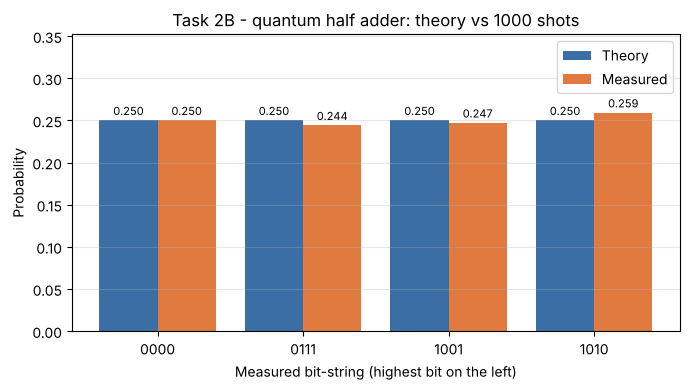

In [11]:
rows = []
for k in sorted(set(theory_b) | set(run_b["counts"])):
    a, b, carry, s = int(k[3]), int(k[2]), int(k[1]), int(k[0])     # c0=A, c1=B, c2=CARRY, c3=SUM
    rows.append({"String c3c2c1c0": k, "A": a, "B": b, "SUM": s, "CARRY": carry,
                 "Correct adder row?": (s == a ^ b) and (carry == a & b),
                 "Theory P": theory_b.get(k, 0.0),
                 "Counts": run_b["counts"].get(k, 0),
                 "Measured P": round(run_b["probs"].get(k, 0.0), 3)})
table_b = pd.DataFrame(rows)
display(table_b)
table_b.to_csv(RESULTS / "task2b_results_table.csv", index=False)
correct = table_b.loc[table_b["Correct adder row?"], "Counts"].sum()
print(f"Shots that are a correct addition: {correct} of {run_b['shots_received']}")
print("TVD (theory vs measured):", round(qh.total_variation_distance(theory_b, run_b["probs"]), 4))

qh.plot_comparison({"Theory": theory_b, "Measured": run_b["probs"]},
                   "Task 2B - quantum half adder: theory vs 1000 shots",
                   path=RESULTS / "task2b_histogram.png")
plt.show()

## Conclusion

* **Part A:** block C was implemented as a CNOT. The H–X–CNOT circuit makes the entangled state $|\Psi^+\rangle$, so the two lines always disagree and the output line is a fair 50/50 random bit.
* **Part B:** our QASM half adder evaluated all four additions in one circuit. Every recorded shot is a correct row of the adder truth table, and the four rows appear with roughly equal frequency.
* A key lesson: phase gates (Z, S) change amplitudes but not measurement probabilities, so they only matter when a later gate makes amplitudes interfere.